# Projeto Prático 2.1 - Aprendizado Supervisionado no Neurônio Perceptron

- Redes Neurais Artificiais 2026.2
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- Escola Superior de Tecnologia - Universidade do Estado do Amazonas
- Enunciado: [rna-2026.2-pp2.1.pdf](rna-2026.2-pp2.1.pdf)

### Equipe

- Bernardo Gontijo Fernandes (http://github.com/bernardo-gontijo)
  - Matrícula: **[2415080002]**
- Mateus Cabral Pinheiro (http://github.com/mateuscpin)
  - Matrícula: **[2415080017]**

### Apresentação

O objetivo deste projeto é implementar o treinamento supervisionado do neurônio Perceptron de Rosenblatt para problemas de classificação, realizar experimentos e avaliar uma solução em um problema não linearmente separável.

### Identificador da Equipe

- Soma dos últimos dígitos das matrículas e calculo do resto da divisão por 4.

**Identificador:** [2 + 7 = 9] -> [9 mod 4 = 1] -> [1]

### Base de Dados e Convenções

Os arquivos têm extensão `.txt`, mas contém dados binários de um `numpy.ndarray`, com dimensões `(m, 1, 3)`. Cada exemplo representa um ponto no plano e seu rótulo: `(x1, x2, yd)`.

- Classe 0: **vermelho**.
- Classe 1: **azul**.
- Parte I: `dados/dataAll20262.txt`.
- Parte II: Como o identificador é [1] `dados/data120262.txt`.
- Parte III: `dados/dataHoldout20262.txt`.

### Bibliotecas

Respeitar a restrição de uso de scikit-learn somente para métricas. O pacote prettytable é recomendado pelo enunciado para a tabela da Parte II.

In [1]:
import pandas as pd
import numpy as np
import random as rd
import math
import matplotlib.pyplot as plt
from prettytable import PrettyTable

## Parte I - Resolvendo um Problema Linearmente Separável

Utilizar o arquivo `dados/dataAll20262.txt` e construir o algoritmo de treinamento do neurônio Perceptron para resolver o problema de classificação proposto.

### Abertura do Dataset

- Carregar o arquivo binário como um array NumPy.
- Visualizar os primeiros exemplos e verificar as dimensões do conjunto.
- Identificar as duas coordenadas de entrada e o rótulo de cada exemplo.

In [2]:
dados_originais = np.load("dados/dataAll20262.txt", allow_pickle=False)
print("Dimensões originais:", dados_originais.shape)

dados = dados_originais.squeeze(axis=1) # Tirar a dimensão intermediaria "1" e separar entradas e rótulos

# Colocar para DataFrame

df = pd.DataFrame(dados, columns=["x1", "x2", "yd"])
df["yd"] = df["yd"].astype(int) # Colocando os rótulos para int

# Nomeando os dados para o treinamento

X = df[["x1", "x2"]].to_numpy(dtype=float)
y = df["yd"].to_numpy(dtype=int)

display(df.head())

print("Quantidade de exemplos por classe:") # Observar a distribuição
print(df["yd"].value_counts().sort_index())


Dimensões originais: (1000, 1, 3)


,x1,x2,yd
0,547.912097,-122.243120,1
1,717.195840,394.736058,0
2,-811.645304,951.244703,0
3,522.279404,572.128611,0
4,-743.772735,-99.228124,0


Quantidade de exemplos por classe:
yd
0    500
1    500
Name: count, dtype: int64


### Visualização Inicial dos Exemplos

- Construir um gráfico de dispersão com todos os exemplos.
- Representar a classe 0 em vermelho e a classe 1 em azul.
- Rotular os eixos e incluir uma legenda que identifique as classes.

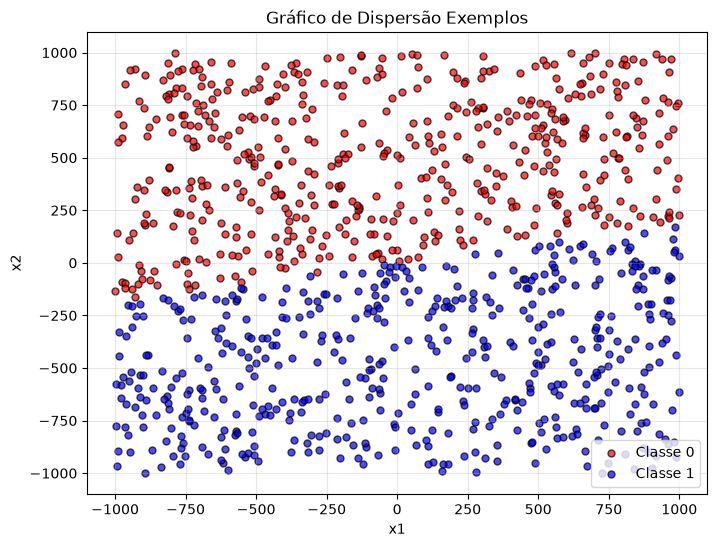

In [3]:
classe_0 = df[df["yd"] == 0]
classe_1 = df[df["yd"] == 1]

plt.figure(figsize=(8, 6))
plt.scatter(classe_0["x1"], classe_0["x2"], color="red", label="Classe 0", s=25, alpha=0.7, edgecolors='black')
plt.scatter(classe_1["x1"], classe_1["x2"], color="blue", label="Classe 1", s=25, alpha=0.7, edgecolors='black')
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Gráfico de Dispersão Exemplos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Construção do Neurônio Perceptron e Configuração Treinamento

- Implementar o cálculo da entrada do neurônio com operações NumPy.
- Implementar a função de ativação degrau com limiar igual a zero.
- Registrar a convenção adotada para os pesos e o termo de polarização.
- Implementar a regra de ajuste dos pesos e a organização do treinamento em épocas.
- Registrar separadamente a quantidade de ajustes e a quantidade de épocas.
- Definir a taxa de aprendizado em **0,1**.
- Inicializar os pesos aleatoriamente com distribuição uniforme no intervalo **(-0,5; +0,5)**.
- Imprimir o vetor inicial de pesos no início da execução.
- Utilizar a função degrau com limiar igual a zero.

In [9]:
class Perceptron:
    def __init__(
        self,
        eta=0.1,
        intervalo_pesos=(-0.5, 0.5),
        n_epocas=None,
        embaralhar=False,
        semente=None
    ):
        self.eta = eta
        self.intervalo_pesos = intervalo_pesos
        self.n_epocas = n_epocas
        self.embaralhar = embaralhar
        self.semente = semente

    def net_input(self, X):
        """Calcula a soma ponderada das entradas mais o bias."""
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        """Aplica o degrau com limiar zero."""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

    def fit(self, X, y):
        """Inicializa os pesos e realiza o treinamento."""
        rng = np.random.default_rng(self.semente)

        minimo, maximo = self.intervalo_pesos

        # Um peso para cada entrada, mais um para o bias.
        self.w_ = rng.uniform(
            minimo,
            maximo,
            size=1 + X.shape[1]
        )

        self.pesos_iniciais_ = self.w_.copy()
        print("Pesos iniciais [bias, w1, w2]:", self.pesos_iniciais_)

        self.ajustes_ = 0
        self.epocas_ = 0

        while (
            self.n_epocas is None
            or self.epocas_ < self.n_epocas
        ):
            ajustes_epoca = 0

            if self.embaralhar:
                indices = rng.permutation(X.shape[0])
            else:
                indices = np.arange(X.shape[0])

            for i in indices:
                xi = X[i]
                desejado = y[i]

                previsto = self.predict(xi)
                erro = desejado - previsto

                if erro != 0:
                    update = self.eta * erro

                    self.w_[1:] += update * xi
                    self.w_[0] += update

                    self.ajustes_ += 1
                    ajustes_epoca += 1

            self.epocas_ += 1

            if self.epocas_ % 1000 == 0:
                print(
                    f"Época {self.epocas_} | "
                    f"Ajustes nesta época: {ajustes_epoca} | "
                    f"Total de ajustes: {self.ajustes_}",
                    flush=True
                )

            # Sem limite definido, treina até uma época sem erros.
            if self.n_epocas is None and ajustes_epoca == 0:
                break

        return self

### Treinamento até a Convergência

- Executar o treinamento até que não haja erros para todos os exemplos do conjunto de treinamento.
- Registrar o vetor de pesos obtido.
- Imprimir o número total de ajustes no vetor de pesos.
- Imprimir o número de épocas até a convergência.

In [10]:
ppn = Perceptron(
    eta=0.1,
    intervalo_pesos=(-0.5, 0.5),
    n_epocas=None,
    embaralhar=False,
    semente=None
)

ppn.fit(X, y)
previsoes = ppn.predict(X)
quantidade_erros = np.count_nonzero(previsoes != y)

print("Pesos finais [bias, w1, w2]: ", ppn.w_)
print("Erros após o treinamento:", quantidade_erros)
print("Total de ajustes:", ppn.ajustes_)
print("Total de épocas:", ppn.epocas_)

Pesos iniciais [bias, w1, w2]: [ 0.43783956  0.46265942 -0.23778144]
Pesos finais [bias, w1, w2]:  [ 3.78395627e-02  7.75035925e+01 -3.86407223e+02]
Erros após o treinamento: 0
Total de ajustes: 42
Total de épocas: 3


### Visualização da Solução
- Apresentar um gráfico com todos os exemplos e a reta que separa as classes, obtida pelo treinamento.
- Classe 0: vermelho; Classe 1: azul 

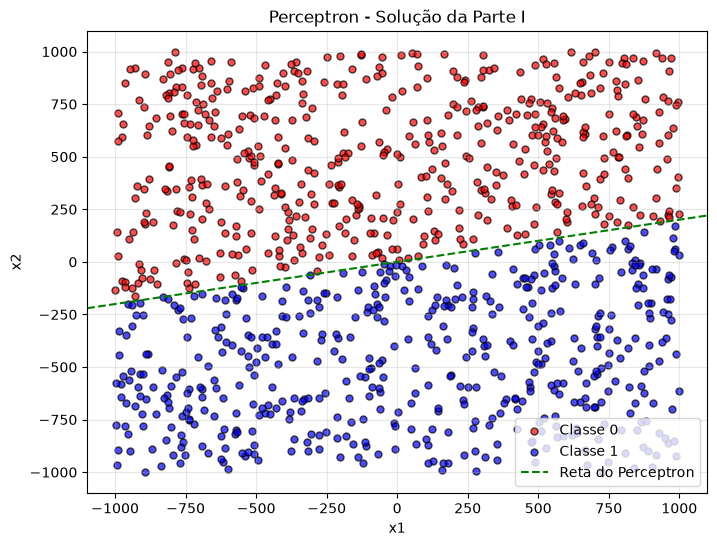

In [11]:
"""Função para desenhar a reta definida pelos pesos aprendidos."""
def plot_decision_boundary(pesos, limites_x):
    bias, w1, w2 = pesos

    if w2 != 0:
        x1 = np.linspace(*limites_x, 100)
        x2 = -(bias + w1 * x1) / w2
        plt.plot(x1, x2, "g--", label="Reta do Perceptron")
        
    elif w1 != 0:
        plt.axvline(-bias / w1, color="green", linestyle="--", label="Reta do Perceptron")

plt.figure(figsize=(8, 6))

plt.scatter(classe_0["x1"], classe_0["x2"], color="red", label="Classe 0", s=25, alpha=0.7, edgecolors='black')
plt.scatter(classe_1["x1"], classe_1["x2"], color="blue", label="Classe 1", s=25, alpha=0.7, edgecolors='black')

# Guarda os limites definidos pelos exemplos.
limites_x = plt.xlim()
limites_y = plt.ylim()

plot_decision_boundary(ppn.w_, limites_x)

plt.xlim(limites_x)
plt.ylim(limites_y)
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.title("Perceptron - Solução da Parte I")
plt.grid(alpha=0.3)
plt.show()

## Parte II - Experimentação

Reutilizar o algoritmo construído na Parte I e utilizar o arquivo correspondente ao identificador da equipe. Comparar seis configurações, executando dez repetições de cada uma.

### Abertura do Dataset: `dados\data120262.txt`

- Carregar os exemplos e conferir as dimensões e os rótulos.


In [12]:
dados1_originais = np.load("dados/data120262.txt", allow_pickle=False)
print("Dimensões originais:", dados1_originais.shape)

dados1 = dados1_originais.squeeze(axis=1) # Tirar a dimensão intermediaria "1" e separar entradas e rótulos

# Colocar para DataFrame

df1 = pd.DataFrame(dados1, columns=["x1", "x2", "yd"])
df1["yd"] = df1["yd"].astype(int) # Colocando os rótulos para int

# Nomeando os dados para o treinamento

X_1 = df1[["x1", "x2"]].to_numpy(dtype=float)
y_1 = df1["yd"].to_numpy(dtype=int)

display(df1.head())

print("Quantidade de exemplos por classe:") # Observar a distribuição
print(df1["yd"].value_counts().sort_index())


Dimensões originais: (1000, 1, 3)


,x1,x2,yd
0,304.598525,-912.449353,0
1,-959.940826,678.425165,0
2,174.286095,-550.589540,0
3,503.584544,-472.615605,1
4,-160.044181,-97.937226,0


Quantidade de exemplos por classe:
yd
0    446
1    554
Name: count, dtype: int64


### Configurações dos Experimentos

Considerar todas as combinações entre as taxas de aprendizado **0,4**, **0,1** e **0,01** e os intervalos de inicialização uniforme **(-100; +100)** e **(-0,5; +0,5)**.

| Configuração | Taxa de aprendizado | Intervalo de pesos |
| --- | --- | --- |
| 1 | 0,4 | (-100; +100) |
| 2 | 0,4 | (-0,5; +0,5) |
| 3 | 0,1 | (-100; +100) |
| 4 | 0,1 | (-0,5; +0,5) |
| 5 | 0,01 | (-100; +100) |
| 6 | 0,01 | (-0,5; +0,5) |

Executar **10 repetições por configuração**, totalizando **60 execuções**.

### Execução e Registro das Repetições

Durante as execuções preliminares com as coordenadas originais, observou-se um custo elevado de treinamento, o que impediu o encerramento do treinamento, que não passava da primeira repetição. Como as coordenadas apresentavam magnitudes próximas de $10^3$, aplicou-se a transformação $X'=X/100$ às duas características, preservando os rótulos e a separabilidade linear. O procedimento modifica a magnitude das atualizações dos pesos em relação ao bias. A mesma transformação foi aplicada às seis configurações, mantendo as taxas de aprendizado, os intervalos de inicialização e as dez repetições solicitadas. Assim, as estatísticas e conclusões apresentadas referem-se aos dados reescalados.

In [25]:
etas = (0.4, 0.1, 0.01)
intervalos_pesos = ((-100, 100), (-0.5, 0.5))
n_repeticoes = 10

registros = [] # Lista apenas para resultados dos experimentos
configuracao = 0 # Inicialmente em 0

"""Reescalonamento das entradas"""
escala_1 = 100.0
X_1_treino = X_1 / escala_1 

for eta in etas:
    for intervalo in intervalos_pesos:
        configuracao += 1
        
        """Demostracao da configuracao de treino"""
        print(f"\nConfiguracao {configuracao}")
        print(f"Taxa de aprendizado: {eta}")
        print(f"Intervalo de Pesos: {intervalo}")

        for repeticao in range(1, n_repeticoes + 1):
            """Semente para manter reprodutibilidade com função para ser de 1 a 60"""
            semente = (configuracao - 1) * n_repeticoes + repeticao

            print(f"\nRepetição {repeticao}")

            ppn1 = Perceptron(
                eta=eta,
                intervalo_pesos=intervalo,
                n_epocas=None,
                embaralhar=False,
                semente=semente
            )
            
            ppn1.fit(X_1_treino, y_1)

            registros.append({
                "configuracao": configuracao,
                "eta": eta,
                "intervalo_pesos": intervalo,
                "repeticao": repeticao,
                "semente": semente,
                "ajustes": ppn1.ajustes_,
                "epocas": ppn1.epocas_
            })

            print(
                f"Ajustes: {ppn1.ajustes_} |" f"Épocas: {ppn1.epocas_}"
            )


Configuracao 1
Taxa de aprendizado: 0.4
Intervalo de Pesos: (-100, 100)

Repetição 1
Pesos iniciais [bias, w1, w2]: [  2.36432494  90.09273927 -71.16807746]
Ajustes: 1689 |Épocas: 320

Repetição 2
Pesos iniciais [bias, w1, w2]: [-47.67757315 -40.30177132  62.84514812]
Ajustes: 1967 |Épocas: 353

Repetição 3
Pesos iniciais [bias, w1, w2]: [-82.87016657 -52.63789868  60.25489304]
Ajustes: 1786 |Épocas: 313

Repetição 4
Pesos iniciais [bias, w1, w2]: [88.61122111  2.26551056 95.24874114]
Ajustes: 83 |Épocas: 8

Repetição 5
Pesos iniciais [bias, w1, w2]: [61.00058475 61.58815795  3.06511221]
Ajustes: 45 |Épocas: 4

Repetição 6
Pesos iniciais [bias, w1, w2]: [  7.63287029 -31.34582604 -26.18655204]
Ajustes: 1858 |Épocas: 337

Repetição 7
Pesos iniciais [bias, w1, w2]: [25.01909332 79.44276019 55.13713805]
Ajustes: 844 |Épocas: 158

Repetição 8
Pesos iniciais [bias, w1, w2]: [-34.60554468  97.45536867 -36.2578323 ]
Ajustes: 1517 |Épocas: 263

Repetição 9
Pesos iniciais [bias, w1, w2]: [ 74.

In [26]:
resultados = pd.DataFrame(registros)

print(f"\nTotal de execuções registradas: {len(resultados)}")
display(resultados)


Total de execuções registradas: 60


,configuracao,eta,intervalo_pesos,repeticao,semente,ajustes,epocas
0,1,0.40,"(-100, 100)",1,1,1689,320
1,1,0.40,"(-100, 100)",2,2,1967,353
2,1,0.40,"(-100, 100)",3,3,1786,313
3,1,0.40,"(-100, 100)",4,4,83,8
4,1,0.40,"(-100, 100)",5,5,45,4
5,1,0.40,"(-100, 100)",6,6,1858,337
6,1,0.40,"(-100, 100)",7,7,844,158
7,1,0.40,"(-100, 100)",8,8,1517,263
8,1,0.40,"(-100, 100)",9,9,110,5
9,1,0.40,"(-100, 100)",10,10,118,6


### Síntese dos Resultados em Tabela

Para cada configuração, calcular sobre as dez execuções:

- Média e Desvio padrão da quantidade de ajustes efetuados no vetor de pesos.
- Menor número de épocas até a convergência.
- Maior número de épocas até a convergência.

Apresentar uma tabela com as colunas **Taxa de Aprendizado**, **Intervalo de Pesos**, **Quantidade de Ajustes (média ± desvio padrão)**, **Mínimo de épocas** e **Máximo de épocas**.

Lembrar da recomendação do prettytable. Preencher a tabela somente com os resultados efetivamente obtidos nos experimentos.

### Boxplots dos Experimentos

- Gráfico reunindo os boxplots das seis configurações a partir dos registros das repetições.
- Identificar a taxa de aprendizado e o intervalo de inicialização de cada configuração.
- Explicitar a variável apresentada no eixo vertical: quantidade de ajustes e/ou épocas até a convergência.
- Rotular os eixos e manter a comparação legível.

### Argumentação sobre as Configurações

- **É possivel afirma acerca da existência de uma configuração melhor ou pior que as demais ou elas são equivalentes?**



## Parte III - Validação Holdout em Problema Não Linearmente Separável

### Abertura do Dataset Holdout: `dados/dataHoldout20262.txt`

- Conferir as dimensões, as coordenadas e os rótulos dos exemplos.

### Visualização Inicial e Separabilidade

- Gráfico inicial com todos os exemplos, evidenciando que o problema não é linearmente separável.

### Preparação dos Dados para Validação Holdout

- Dividir aleatoriamente os exemplos em **70% para treinamento** e **30% para teste**.
- **Random Seed:** 1.
- Registrar a quantidade de exemplos em cada partição.
- Reservar o conjunto de teste para a avaliação.

### Configuração do Perceptron e Fundamentação

- Utilizar a função de ativação degrau com limiar igual a zero.
- Inicializar os pesos aleatoriamente com distribuição uniforme em **(-0,5; +0,5)**.
- Definir a taxa de aprendizado conforme recomendações da literatura.
- Apresentar a referência consultada e justificar a escolha da taxa de aprendizado.
- Configurar o treinamento para **100 épocas**.

**Taxa de aprendizado escolhida:**

**Justificativa e referência:**

### Treinamento por 100 épocas

- Executar o algoritmo sobre o conjunto de treinamento por **100 épocas**.
- Apresentar os exemplos de treinamento em **ordem aleatória a cada época**.
- Registrar os pesos obtidos ao final do treinamento para realizar as previsões e construir os gráficos da solução.

### Obtendo Previsões no Conjunto de Teste

- Obter a saída do neurônio para todos os exemplos do conjunto de teste.
- Comparar as previsões com os respectivos rótulos desejados.
- Manter as previsões e os rótulos correspondentes disponíveis para calcular as métricas.

### Matriz de Confusão do Conjunto de Teste

- Apresentar a matriz de confusão das previsões efetuadas no conjunto de teste.
- Identificar as classes e os eixos de valores reais e previstos.

### Acurácia, Precisão, Revocação e F-Score

Há uma ambiguidade no enunciado: esta etapa começa solicitando previsões de teste, mas a questão 2 menciona os dados de treinamento e a questão 3 remete é anterior. Organizar os resultados de forma a identificar explicitamente o conjunto avaliado.

- Calcular a **acurácia**, a **precisão**, a **revocação** e o **F-Score** no conjunto de teste, para sustentar a discussão solicitada sobre esse conjunto.
- Apresentar também as mesmas métricas no conjunto de treinamento, contemplando a redação das questões 2 e 3.
- Informar a classe positiva ou a estratégia de agregação utilizada nas métricas.
- Utilizar sklearn.metrics apenas para esses cálculos.
- Dispor os resultados de treino e teste com identificação clara, sem misturá-los.

### Qualidade da Solução perante o Conjunto de Testes

### Visualização da Solução: Treinamento e Teste

Apresentar **dois gráficos lado a lado**, utilizando a mesma solução obtida pelo neurônio:

1. Dados de Treinamento.
2. Dados de Teste.

Manter vermelho para a classe 0 e azul para a classe 1. Identificar eixos, classes, reta e partição em cada gráfico.

## Referências

- Enunciado do Projeto Prático 2.1: [PDF disponibilizado](rna-2026.2-pp2.1.pdf).
- Referências de literatura consultadas pela equipe: **[preencher]**.
- <https://numpy.org/>
- <https://numpy.org/doc/stable/>
- <https://matplotlib.org/3.3.0/api/_as_gen/matplotlib.pyplot.scatter.html>
- <https://jakevdp.github.io/PythonDataScienceHandbook/04.02-simple-scatter-plots.html>
- <https://urapython.github.io/-perceptron-with-python-a-tutorial/>
- <https://www.cs.cornell.edu/courses/cs4780/2018fa/lectures/lecturenote03.html>
- <https://cvw.cac.cornell.edu/SciML/mlp/perceptron>